In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import os

print("Tudo importado!")

Tudo importado!


In [2]:
caminho_base = "."

sets = {
    "Z": {"nome": "Set A - Olhos abertos", "rotulo": 0},
    "O": {"nome": "Set B - Olhos fechados", "rotulo": 1},
}

sinais = []
rotulos = []
origens = []

for pasta, info in sets.items():
    caminho_pasta = os.path.join(caminho_base, pasta)
    arquivos = sorted([f for f in os.listdir(caminho_pasta) if f.lower().endswith('.txt')])
    
    for arquivo in arquivos:
        caminho_arquivo = os.path.join(caminho_pasta, arquivo)
        sinal = np.loadtxt(caminho_arquivo)
        sinais.append(sinal)
        rotulos.append(info["rotulo"])
        origens.append(info["nome"])

sinais = np.array(sinais, dtype=np.float32)
rotulos = np.array(rotulos, dtype=np.int64)

print(f"Total de sinais carregados: {len(sinais)}")
print(f"\nDistribuição das classes:")
print(f"  Classe 0 (olhos abertos):  {(rotulos == 0).sum()} sinais")
print(f"  Classe 1 (olhos fechados): {(rotulos == 1).sum()} sinais")

Total de sinais carregados: 200

Distribuição das classes:
  Classe 0 (olhos abertos):  100 sinais
  Classe 1 (olhos fechados): 100 sinais


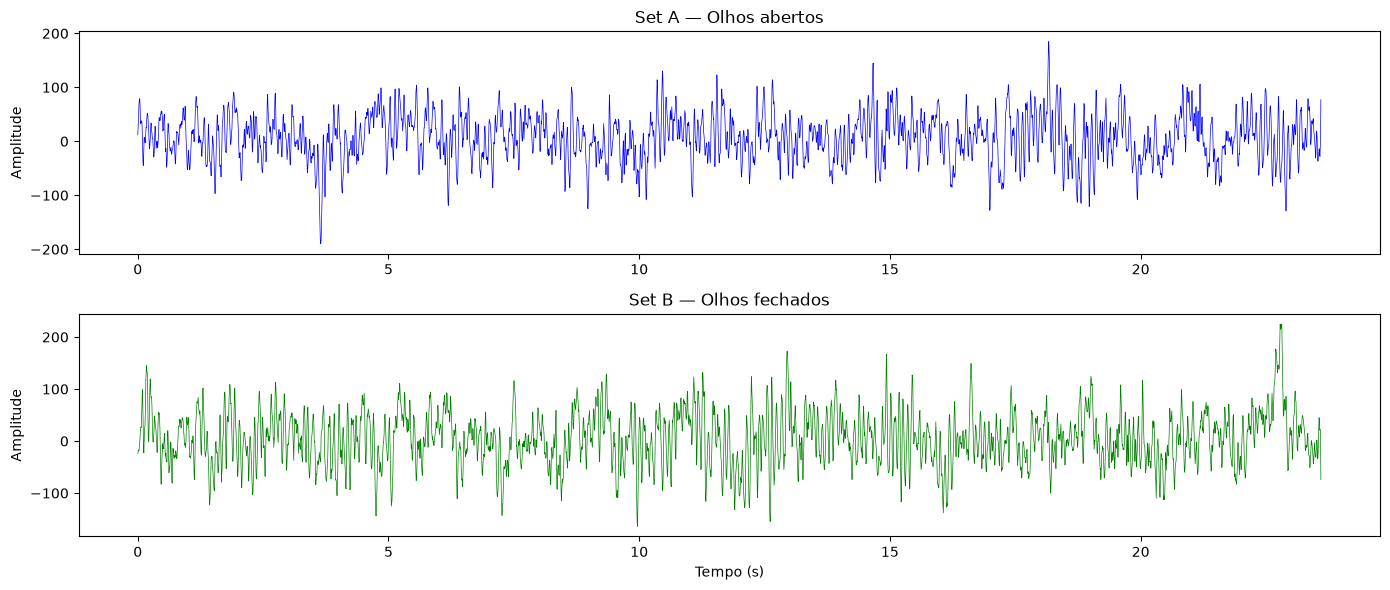

In [3]:
t_eeg = np.arange(4097) / 173.61

fig, eixos = plt.subplots(2, 1, figsize=(14, 6))

eixos[0].plot(t_eeg, sinais[0], linewidth=0.5, color='blue')
eixos[0].set_title("Set A — Olhos abertos")
eixos[0].set_ylabel("Amplitude")

eixos[1].plot(t_eeg, sinais[100], linewidth=0.5, color='green')
eixos[1].set_title("Set B — Olhos fechados")
eixos[1].set_ylabel("Amplitude")
eixos[1].set_xlabel("Tempo (s)")

plt.tight_layout()
plt.show()

In [4]:
duracao_janela = 2.0
taxa = 173.61
pontos_por_janela = int(duracao_janela * taxa)

print(f"Duração da janela: {duracao_janela} s")
print(f"Pontos por janela: {pontos_por_janela}")

janelas = []
rotulos_janelas = []

for i in range(len(sinais)):
    sinal = sinais[i]
    rotulo = rotulos[i]
    num_janelas = len(sinal) // pontos_por_janela
    
    for j in range(num_janelas):
        inicio = j * pontos_por_janela
        fim = inicio + pontos_por_janela
        janela = sinal[inicio:fim]
        janelas.append(janela)
        rotulos_janelas.append(rotulo)

janelas = np.array(janelas, dtype=np.float32)
rotulos_janelas = np.array(rotulos_janelas, dtype=np.int64)

print(f"\nTotal de janelas: {len(janelas)}")
print(f"Formato de cada janela: {janelas[0].shape}")
print(f"Classe 0 (olhos abertos):  {(rotulos_janelas == 0).sum()} janelas")
print(f"Classe 1 (olhos fechados): {(rotulos_janelas == 1).sum()} janelas")

Duração da janela: 2.0 s
Pontos por janela: 347

Total de janelas: 2200
Formato de cada janela: (347,)
Classe 0 (olhos abertos):  1100 janelas
Classe 1 (olhos fechados): 1100 janelas


In [5]:
janelas_treino, janelas_teste, rot_treino, rot_teste = train_test_split(
    janelas, rotulos_janelas, test_size=0.2, random_state=42, stratify=rotulos_janelas
)

print(f"Treino: {len(janelas_treino)} janelas")
print(f"Teste:  {len(janelas_teste)} janelas")
print(f"Treino — Classe 0: {(rot_treino == 0).sum()}, Classe 1: {(rot_treino == 1).sum()}")
print(f"Teste  — Classe 0: {(rot_teste == 0).sum()}, Classe 1: {(rot_teste == 1).sum()}")

Treino: 1760 janelas
Teste:  440 janelas
Treino — Classe 0: 880, Classe 1: 880
Teste  — Classe 0: 220, Classe 1: 220


In [6]:
media_treino = janelas_treino.mean()
desvio_treino = janelas_treino.std()

janelas_treino_norm = (janelas_treino - media_treino) / desvio_treino
janelas_teste_norm = (janelas_teste - media_treino) / desvio_treino

print(f"Média do treino: {media_treino:.4f}")
print(f"Desvio padrão: {desvio_treino:.4f}")
print(f"\nApós normalização:")
print(f"  Treino — média: {janelas_treino_norm.mean():.4f}, desvio: {janelas_treino_norm.std():.4f}")
print(f"  Teste  — média: {janelas_teste_norm.mean():.4f}, desvio: {janelas_teste_norm.std():.4f}")

Média do treino: -8.9434
Desvio padrão: 60.7234

Após normalização:
  Treino — média: 0.0000, desvio: 1.0000
  Teste  — média: -0.0366, desvio: 0.9930


In [7]:
# Converter para tensores
X_treino = torch.FloatTensor(janelas_treino_norm).unsqueeze(1)  # adiciona canal
y_treino = torch.LongTensor(rot_treino)
X_teste = torch.FloatTensor(janelas_teste_norm).unsqueeze(1)
y_teste = torch.LongTensor(rot_teste)

print(f"X_treino: {X_treino.shape}  (batch, canal, pontos)")
print(f"X_teste:  {X_teste.shape}")

# DataLoaders
dataset_treino = TensorDataset(X_treino, y_treino)
dataset_teste = TensorDataset(X_teste, y_teste)

loader_treino = DataLoader(dataset_treino, batch_size=64, shuffle=True)
loader_teste = DataLoader(dataset_teste, batch_size=64, shuffle=False)

print(f"\nBatches de treino: {len(loader_treino)}")
print(f"Batches de teste: {len(loader_teste)}")

X_treino: torch.Size([1760, 1, 347])  (batch, canal, pontos)
X_teste:  torch.Size([440, 1, 347])

Batches de treino: 28
Batches de teste: 7


In [8]:
class DatasetAugmentado(torch.utils.data.Dataset):
    """
    Dataset que aplica augmentation aleatório a cada leitura.
    Só para treino — teste continua sem augmentation.
    """
    def __init__(self, sinais, rotulos, augmentar=True):
        self.sinais = sinais      # tensores já normalizados
        self.rotulos = rotulos
        self.augmentar = augmentar
    
    def __len__(self):
        return len(self.sinais)
    
    def __getitem__(self, idx):
        sinal = self.sinais[idx].clone()  # clone para não alterar o original
        rotulo = self.rotulos[idx]
        
        if self.augmentar:
            # Transformação 1: adicionar ruído gaussiano leve
            # Desvio de 0.05 significa ruído com 5% da amplitude normalizada
            ruido = torch.randn_like(sinal) * 0.05
            sinal = sinal + ruido
            
            # Transformação 2: escalar amplitude aleatoriamente entre 0.8x e 1.2x
            escala = 0.8 + torch.rand(1).item() * 0.4  # valor entre 0.8 e 1.2
            sinal = sinal * escala
        
        return sinal, rotulo

# Cria dataset augmentado para treino (com augmentation)
dataset_treino_aug = DatasetAugmentado(X_treino, y_treino, augmentar=True)

# Teste continua sem augmentation (usando o TensorDataset normal que já existe)
# dataset_teste já foi criado na célula 7

# Recria o DataLoader de treino usando o dataset augmentado
loader_treino = DataLoader(dataset_treino_aug, batch_size=64, shuffle=True)

# Verifica: lê a mesma amostra duas vezes
amostra1, _ = dataset_treino_aug[0]
amostra2, _ = dataset_treino_aug[0]
iguais = torch.equal(amostra1, amostra2)
print(f"Duas leituras da mesma amostra são iguais? {iguais}")
print("(Se False, o augmentation está funcionando)")
print(f"\nBatches de treino: {len(loader_treino)}")

Duas leituras da mesma amostra são iguais? False
(Se False, o augmentation está funcionando)

Batches de treino: 28


In [9]:
class CNN1D_EEG(nn.Module):
    def __init__(self):
        super().__init__()
        
        # Camada 1: kernel grande, vê padrões lentos no sinal bruto
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=16, kernel_size=21, padding=10)
        
        # Camada 2: kernel médio, combina padrões da camada 1
        self.conv2 = nn.Conv1d(in_channels=16, out_channels=32, kernel_size=11, padding=5)
        
        # Camada 3: kernel menor, refina para características abstratas
        self.conv3 = nn.Conv1d(in_channels=32, out_channels=64, kernel_size=7, padding=3)
        
        self.pool = nn.MaxPool1d(kernel_size=2)
        
        # Calcula automaticamente o tamanho após as 3 convoluções + 3 poolings
        with torch.no_grad():
            ficticio = torch.zeros(1, 1, pontos_por_janela)
            ficticio = self.pool(self.conv1(ficticio))
            ficticio = self.pool(self.conv2(ficticio))
            ficticio = self.pool(self.conv3(ficticio))
            tamanho_achatado = ficticio.view(1, -1).shape[1]
        
        print(f"Tamanho após achatamento: {tamanho_achatado}")
        
        self.fc1 = nn.Linear(tamanho_achatado, 64)
        self.fc2 = nn.Linear(64, 2)
        
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=0.4)
    
    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        
        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

modelo = CNN1D_EEG()
print(modelo)
total_params = sum(p.numel() for p in modelo.parameters())
print(f"\nTotal de parâmetros: {total_params:,}")

Tamanho após achatamento: 2752
CNN1D_EEG(
  (conv1): Conv1d(1, 16, kernel_size=(21,), stride=(1,), padding=(10,))
  (conv2): Conv1d(16, 32, kernel_size=(11,), stride=(1,), padding=(5,))
  (conv3): Conv1d(32, 64, kernel_size=(7,), stride=(1,), padding=(3,))
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2752, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=2, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.4, inplace=False)
)

Total de parâmetros: 196,738


In [10]:
criterio = nn.CrossEntropyLoss()
otimizador = optim.Adam(modelo.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(otimizador, step_size=8, gamma=0.5)

num_epocas = 50
for epoca in range(num_epocas):
    modelo.train()
    perda_acumulada = 0.0
    acertos = 0
    total = 0
    
    for entradas, rotulos_batch in loader_treino:
        otimizador.zero_grad()
        saidas = modelo(entradas)
        perda = criterio(saidas, rotulos_batch)
        perda.backward()
        otimizador.step()
        
        perda_acumulada += perda.item()
        _, previstos = saidas.max(1)
        acertos += (previstos == rotulos_batch).sum().item()
        total += rotulos_batch.size(0)
    
    scheduler.step()
    lr_atual = otimizador.param_groups[0]['lr']
    perda_media = perda_acumulada / len(loader_treino)
    acuracia = 100 * acertos / total
    print(f"Época {epoca+1}/{num_epocas} — Perda: {perda_media:.4f} — Acurácia: {acuracia:.2f}% — LR: {lr_atual:.6f}")

print("\nTreinamento concluído!")

Época 1/50 — Perda: 0.5599 — Acurácia: 68.01% — LR: 0.001000
Época 2/50 — Perda: 0.4183 — Acurácia: 80.85% — LR: 0.001000
Época 3/50 — Perda: 0.3692 — Acurácia: 83.52% — LR: 0.001000
Época 4/50 — Perda: 0.3607 — Acurácia: 83.75% — LR: 0.001000
Época 5/50 — Perda: 0.3383 — Acurácia: 85.40% — LR: 0.001000
Época 6/50 — Perda: 0.3142 — Acurácia: 85.45% — LR: 0.001000
Época 7/50 — Perda: 0.3066 — Acurácia: 86.42% — LR: 0.001000
Época 8/50 — Perda: 0.2997 — Acurácia: 86.48% — LR: 0.000500
Época 9/50 — Perda: 0.2586 — Acurácia: 88.35% — LR: 0.000500
Época 10/50 — Perda: 0.2664 — Acurácia: 88.47% — LR: 0.000500
Época 11/50 — Perda: 0.2424 — Acurácia: 89.09% — LR: 0.000500
Época 12/50 — Perda: 0.2381 — Acurácia: 89.66% — LR: 0.000500
Época 13/50 — Perda: 0.2282 — Acurácia: 90.74% — LR: 0.000500
Época 14/50 — Perda: 0.2213 — Acurácia: 91.08% — LR: 0.000500
Época 15/50 — Perda: 0.1940 — Acurácia: 92.05% — LR: 0.000500
Época 16/50 — Perda: 0.1895 — Acurácia: 91.93% — LR: 0.000250
Época 17/50 — Per

In [11]:
modelo.eval()
acertos = 0
total = 0

with torch.no_grad():
    for entradas, rotulos_batch in loader_teste:
        saidas = modelo(entradas)
        _, previstos = saidas.max(1)
        acertos += (previstos == rotulos_batch).sum().item()
        total += rotulos_batch.size(0)

acuracia_teste = 100 * acertos / total
print(f"Acurácia no teste: {acuracia_teste:.2f}%")
print(f"Acertos: {acertos}/{total}")

Acurácia no teste: 85.23%
Acertos: 375/440


In [12]:
from sklearn.metrics import confusion_matrix, classification_report

modelo.eval()

todas_previsoes = []
todos_rotulos = []

with torch.no_grad():
    for entradas, rotulos_batch in loader_teste:
        saidas = modelo(entradas)
        _, previstos = saidas.max(1)
        todas_previsoes.extend(previstos.numpy())
        todos_rotulos.extend(rotulos_batch.numpy())

nomes_classes = ["Olhos abertos", "Olhos fechados"]
cm = confusion_matrix(todos_rotulos, todas_previsoes)

print("=== MATRIZ DE CONFUSÃO ===\n")
print(f"{'':>16} {'Prev Abertos':>14} {'Prev Fechados':>14}")
for i, nome in enumerate(nomes_classes):
    print(f"{nome:>16} {cm[i][0]:>14} {cm[i][1]:>14}")

print(f"\n=== RELATÓRIO DE CLASSIFICAÇÃO ===\n")
print(classification_report(todos_rotulos, todas_previsoes, target_names=nomes_classes))

=== MATRIZ DE CONFUSÃO ===

                   Prev Abertos  Prev Fechados
   Olhos abertos            189             31
  Olhos fechados             34            186

=== RELATÓRIO DE CLASSIFICAÇÃO ===

                precision    recall  f1-score   support

 Olhos abertos       0.85      0.86      0.85       220
Olhos fechados       0.86      0.85      0.85       220

      accuracy                           0.85       440
     macro avg       0.85      0.85      0.85       440
  weighted avg       0.85      0.85      0.85       440



In [13]:
total_params = sum(p.numel() for p in modelo.parameters())
print(f"Total de parâmetros: {total_params:,}")

Total de parâmetros: 196,738


In [14]:
torch.save(modelo.state_dict(), "modelo_a_vs_b.pth")
print("Modelo A vs B salvo!")

Modelo A vs B salvo!
